# Unsupervised — Clustering (kolom angka)
**Kapan dipakai:** diminta mengelompokkan data (pelanggan, wilayah, produk) tanpa label,
lalu menjelaskan tiap kelompok.

**Idenya:** baris yang jaraknya dekat dimasukkan ke kelompok (cluster) yang sama. Skala
kolom disamakan dulu supaya kolom bernilai besar tidak mendominasi jarak.

**Langkah:**
1. Baca data, samakan skala.
2. Pilih jumlah cluster dengan silhouette (makin tinggi makin baik).
3. Latih model, lihat profil tiap cluster, simpan label cluster.

**Data demo:** Wine (13 kolom kimia, `cultivar` = jenis anggur asli, hanya untuk cek).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN, HDBSCAN, AgglomerativeClustering, Birch, KMeans
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/unsupervised"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/wine.csv"
# DATA_CSV = f"{DATA_FOLDER}/moons_SINTETIS.csv"    # bentuk bulan sabit: LABEL_COL = "true"

LABEL_COL = "cultivar"   # hanya untuk cek, kolom lain dipakai sebagai feature
N_CLUSTERS = 3
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
print(data.shape)
missing_per_column = data.isna().sum()
print("missing total:", missing_per_column.sum())
data.head()

(178, 14)
missing total: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


## Langkah 1 — samakan skala
Gambar PCA 2D = semua kolom diringkas jadi 2 sumbu, hanya untuk dilihat.

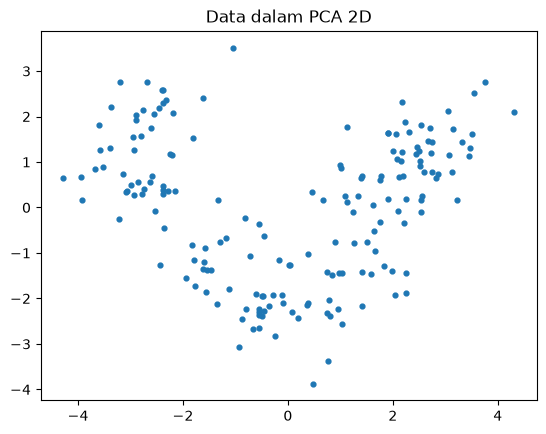

In [4]:
X = data.drop(columns=[LABEL_COL])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=12)
plt.title("Data dalam PCA 2D")
plt.show()

## Langkah 2 — pilih jumlah cluster
Silhouette tinggi dan Davies-Bouldin rendah = cluster rapat dan saling terpisah.
Pilih angka terbaik, tulis di `N_CLUSTERS` pada Konfigurasi.

In [5]:
for count in range(2, 9):
    kmeans = KMeans(n_clusters=count, n_init=10, random_state=SEED)
    trial_labels = kmeans.fit_predict(X_scaled)
    silhouette = silhouette_score(X_scaled, trial_labels)
    davies = davies_bouldin_score(X_scaled, trial_labels)
    print(count, "cluster | silhouette:", round(silhouette, 3), "| DB:", round(davies, 3))

2 cluster | silhouette: 0.259 | DB: 1.526
3 cluster | silhouette: 0.285 | DB: 1.389
4 cluster | silhouette: 0.26 | DB: 1.797
5 cluster | silhouette: 0.202 | DB: 1.808
6 cluster | silhouette: 0.237 | DB: 1.554


7 cluster | silhouette: 0.204 | DB: 1.661
8 cluster | silhouette: 0.157 | DB: 1.741


## Langkah 3 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.
DBSCAN/HDBSCAN menentukan jumlah cluster sendiri dan memberi label -1 untuk "noise".

silhouette: 0.285
0    65
2    62
1    51
Name: count, dtype: int64


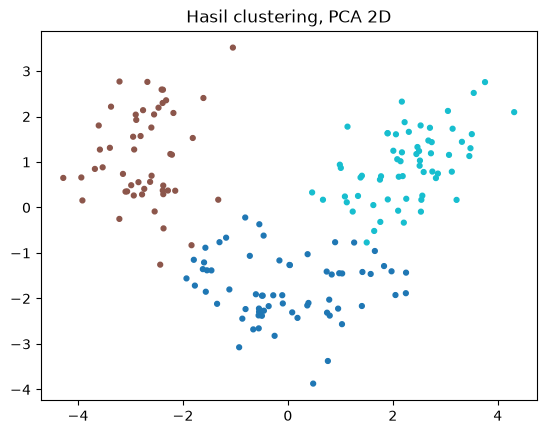

In [6]:
model = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
# model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
# model = GaussianMixture(n_components=N_CLUSTERS, random_state=SEED)   # cluster lonjong
# model = SpectralClustering(n_clusters=N_CLUSTERS, affinity="nearest_neighbors",
#                            random_state=SEED)                       # bentuk bulan sabit
# model = Birch(n_clusters=N_CLUSTERS)                               # data sangat besar
# model = DBSCAN(eps=2.0, min_samples=8)                             # eps perlu dicoba-coba
# model = HDBSCAN(min_cluster_size=10)

labels = model.fit_predict(X_scaled)
print("silhouette:", round(silhouette_score(X_scaled, labels), 3))
print(pd.Series(labels).value_counts())

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="tab10", s=12)
plt.title("Hasil clustering, PCA 2D")
plt.show()

## Profil tiap cluster
Rata-rata tiap kolom per cluster = bahan untuk menjelaskan "cluster 0 itu yang seperti apa".

In [7]:
profile = X.groupby(labels).mean()
profile.round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


## Simpan label cluster

In [8]:
submission = pd.DataFrame()
submission["row"] = data.index
submission["cluster"] = labels
submission.to_csv("submission.csv", index=False)
submission.head()

,row,cluster
0,0,2
1,1,2
2,2,2
3,3,2
4,4,2


## Cek dengan kunci jawaban (HAPUS saat lomba)
ARI = kemiripan cluster dengan label asli (1 = sama persis, 0 = acak).

In [9]:
print("ARI:", round(adjusted_rand_score(data[LABEL_COL], labels), 3))
pd.crosstab(labels, data[LABEL_COL], rownames=["cluster"])

ARI: 0.897


cultivar,class_0,class_1,class_2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0
